# 📘 Week 9 Practical Workbook

## Stability of Ordinary Differential Equations and Boundary Value Problems

This workbook connects Notes 9.1-9.4 through runnable engineering activities and analytical problems.

Begin the
guided A activities in Monday's workshop, continue the B problems during Wednesday's
practical, and finish the revision section at home.


# 🧭 Weekly workflow and expected effort

| Stage | Suggested use | Approximate time |
|---|---|---:|
| Before Monday | Run Notes 9.1–9.4 and record questions | 2 hours |
| Monday workshop | Guided Activities 1A–5A, demonstrations and discussion | 2 hours |
| Wednesday practical | Problem-solving Activities 1B–5B with tutor support | 2 hours |
| Revision | Finish problems and complete Activities 6–7 | 3 hours |

Every activity follows **Predict → Change or select → Run → Inspect → Explain →
Validate**. Monday does not require every A activity to be completed in full.


# 🧩 How the A and B activities work

- **A activities are guided explorations.** Change the marked `TODO` values, run the cell,
  and explain the behaviour visible in the figure.
- **B activities are problems to solve.** All datasets, candidate settings and functions
  are supplied. The starter choice runs, but it is not necessarily defensible.
- Each B problem includes progressive hints and a visualisation of the current selection.
- A strong answer reports units, evidence, assumptions and limitations—not only a method
  name or number.
- Activities **4 and 5+** are revision and integration tasks. They are intentionally less
  scaffolded and are useful preparation for later assessment.


# 🎯 Learning objectives

By completing this workbook, you should be able to:

- Evalute the forward error and backwards error of algorithms in linear algebra;
- Use perturbation theory to predict stability of ODEs;
- explain how optimial step size relates to stability;
- explain how multiple scales can exist in an ODE and the impact this has on the step sizes associated with explicit methods;
- Recognise that stability is set by the short time scale feature;
- Formulate the equations required for each step of a Euler or RK4 based solution of an ODE;
- Recognise the difference between an implicit and explicit method;
- Formulate a backward implicit Euler method and calculate its stability;
- Apply linearisation to formulate a semi-implicit Euler method.
- Reduce a boundary value problem to an initial value problem by guessing unknown initial condition(s);
- Formulate sensitivity equations for the solution of Boudnary value problems and construct the framework for an iterative shooting method.


# 📚 Week 9 notes map

| Workbook pair | Supporting notes | Main skill |
|---|---|---|
| 1A–1B | 9.1 Stability of ODEs | Understanding of stability, perturbation analysis |
| 2A–2B | 9.2 Stiff ODEs | Multile solution scales, challenges of stability |
| 3A–2B | 9.3 Implicit Solution Method | formulation/implementation of implicit method and impact on stability |
| 4A–3B | 9.4 Boundary Value Problems | Setting up a problems as an initial value problem |


# 🟧 Monday workshop — guided exploration

Activities 1A–5A contain valid `TODO` values. Change one value at a time, predict the
effect before running, and record what the figure or table shows.


## Activity 1A — Stability of Explicit Euler Solution to $y'(t) = Ay(t) + B\sin(t)$

**Predict first:** What impact will changes to the time-step and the coefficients A and B have on the solution, it's stability and accuracy?




Basic code for Euler's Method is relatively simple, but line 14 - the update - depends on the particular ODE you are trying to solve.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def solve_euler(A, B, h, T=10.0, y0=0.0):
    """
    Solve y'(t) = A y(t) + B sin(t) using explicit Euler.
    """
    N = int(T / h)
    t = np.linspace(0, T, N+1)
    y = np.zeros(N+1)
    y[0] = y0

    for n in range(N):
        y[n+1] = y[n] + h * (A * y[n] + B * np.sin(t[n]))

    return t, y

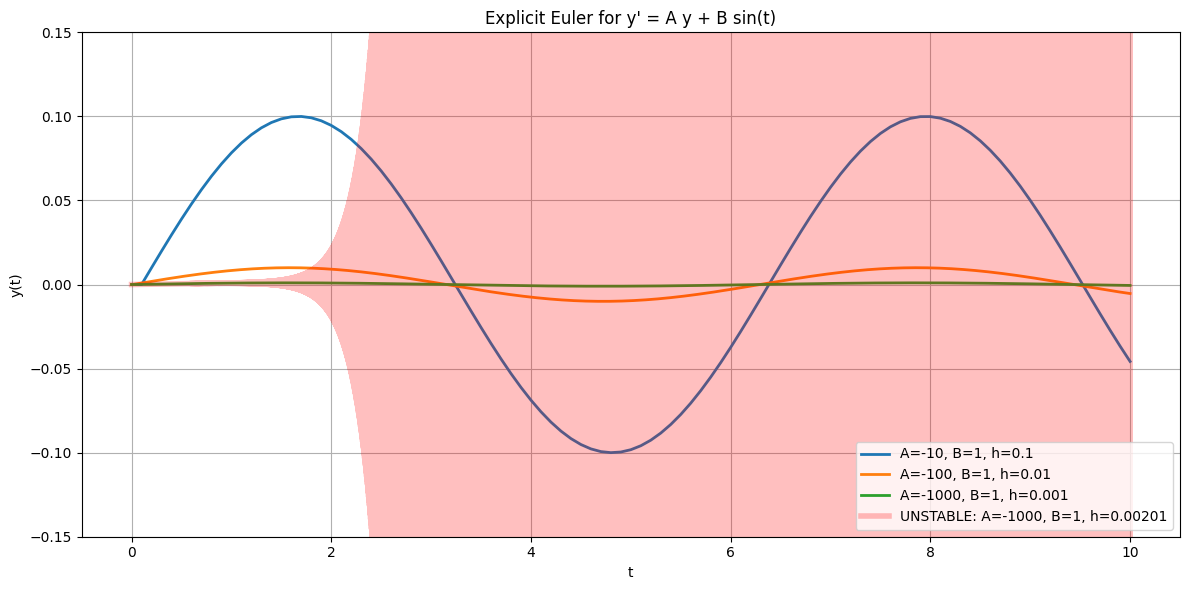

In [ ]:
# ---------------------------------------------------------
# Parameter sets
# ---------------------------------------------------------
stable_cases = [
    {"A": -10,   "B": 1, "h": 0.1},
    {"A": -100,  "B": 1, "h": 0.01},
    {"A": -1000, "B": 1, "h": 0.001},   # stiff but stable
]

blowup_case = {"A": -1000, "B": 1, "h": 0.00201}  # unstable

plt.figure(figsize=(12, 6))

# Plot stable cases normally
for case in stable_cases:
    A, B, h = case["A"], case["B"], case["h"]
    t, y = solve_euler(A, B, h)
    plt.plot(t, y, label=f"A={A}, B={B}, h={h}", linewidth=2)

# Plot blow-up case with transparency and background style
A, B, h = blowup_case["A"], blowup_case["B"], blowup_case["h"]
t, y = solve_euler(A, B, h)
plt.plot(t, y, color="red", alpha=0.25, linewidth=4,
         label=f"UNSTABLE: A={A}, B={B}, h={h}")

plt.title("Explicit Euler for y' = A y + B sin(t)")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.ylim(-0.15,0.15)
plt.grid(True)
plt.legend()
plt.tight_layout()


plt.title("Explicit Euler for y' = A y + B sin(t)")
plt.xlabel("t")
plt.ylabel("y(t)")
plt.ylim(-0.15,0.15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

plt.show()

### Stability Table for Explicit Euler  
ODE:  y'(t) = A y(t) + B sin(t)

| A        | Stability limit for h (max stable h) | Steps required for t = 0 → 10 |
|----------|--------------------------------------|-------------------------------|
| -10      | h < 0.2                              | N = 10 / 0.2   = 50           |
| -100     | h < 0.02                             | N = 10 / 0.02  = 500          |
| -1000    | h < 0.002                            | N = 10 / 0.002 = 5000         |

**Ask yourself**: What impact does the coefficient $A$ have on the problem?

## Activity 2A — Why Does an ODE Become Stiff




The analytical solution to the ODE $y'(t) = Ay(t) + B\sin(t)$, is
$$
\boxed{
y(t)= \left(y_0 + \frac{B}{A^2 + 1}\right)e^{A t}
  -\frac{B}{A^2 + 1}\big(A\sin t + \cos t\big)
}$$

The term  
  $$\left(y_0 + \frac{B}{A^2 + 1}\right)e^{A t}$$  
  is the **stiff transient**, which decays extremely fast when $A\ll 0$.

The term  
  $$-\frac{B}{A^2 + 1}\big(A\sin t + \cos t\big)$$  
  is the **steady‑state forced response**.

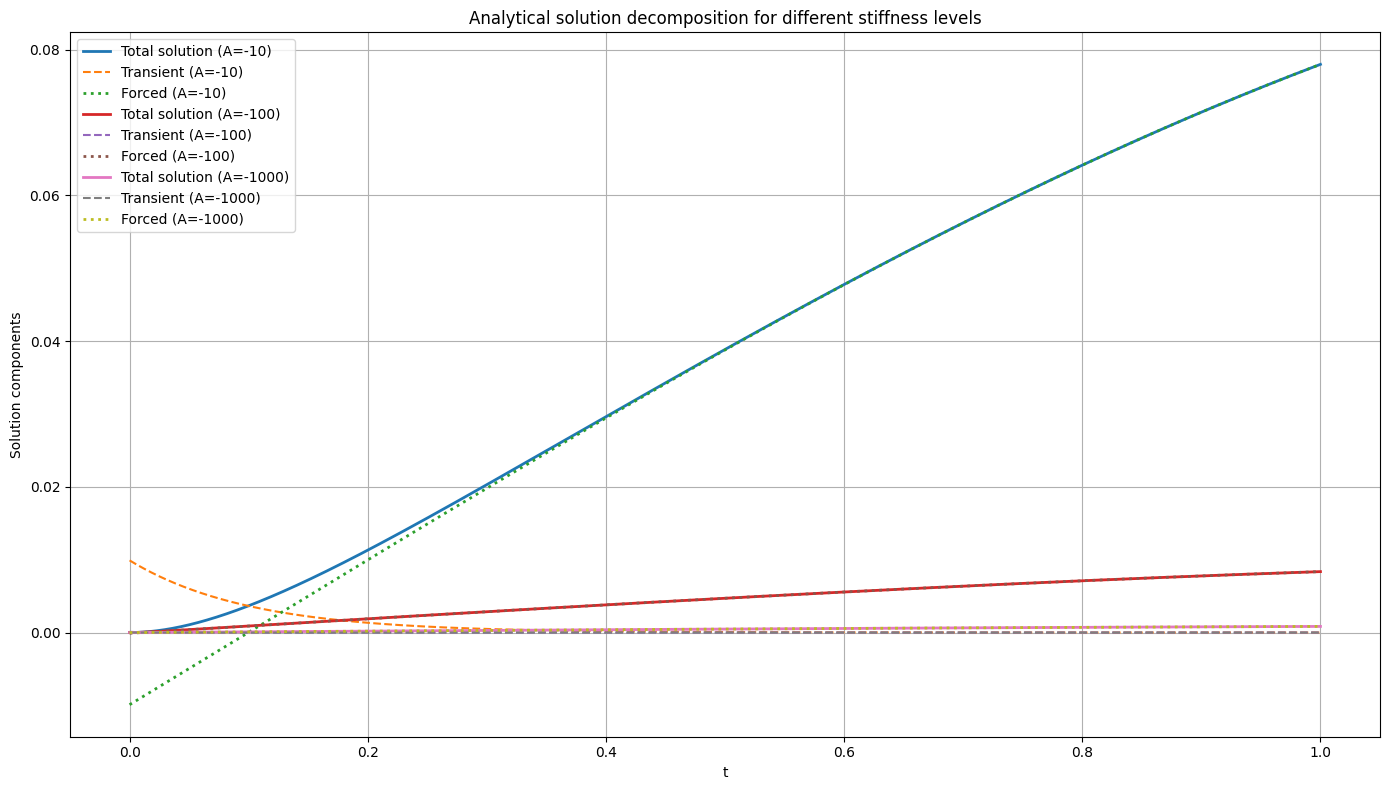

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Analytical solution components
def analytical_solution(A, B, y0, t):
    # Transient (homogeneous)
    y_transient = (y0 + B/(A**2 + 1)) * np.exp(A * t)

    # Forced (particular)
    y_forced = -(B/(A**2 + 1)) * (A * np.sin(t) + np.cos(t))

    # Total
    y_total = y_transient + y_forced

    return y_transient, y_forced, y_total

# ---------------------------------------------------------
# Parameters
# ---------------------------------------------------------
A_values = [-10, -100, -1000]
B = 1
y0 = 0
t = np.linspace(0, 1, 2000)

# ---------------------------------------------------------
# Plot for each A
# ---------------------------------------------------------
plt.figure(figsize=(14, 8))

for A in A_values:
    y_transient, y_forced, y_total = analytical_solution(A, B, y0, t)

    plt.plot(t, y_total, linewidth=2, label=f"Total solution (A={A})")
    plt.plot(t, y_transient, '--', linewidth=1.5, label=f"Transient (A={A})")
    plt.plot(t, y_forced, ':', linewidth=2, label=f"Forced (A={A})")

plt.title("Analytical solution decomposition for different stiffness levels")
plt.xlabel("t")
plt.ylabel("Solution components")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


A = −10 (low stiffness)
* Transient decays slowly.
* Forced term becomes visible early.
* Total solution shows a mix of transient + forcing for a long time.

A = −100 (medium stiffness)
* Transient collapses quickly.
* Forced term dominates after a short transient.
* Total solution becomes almost purely sinusoidal.

A = −1000 (high stiffness)
* Transient disappears almost instantly.
* Total solution ≈ forced term for nearly all [ t > 0.01 ].
* This is the classic stiff behaviour.

## Activity 3A — Implicit Euler step size and stability

Euler's method advances from one numerical state to the next using the current slope.

For the current ODE:

$$\frac{dT}{dt} = \frac{H-k(T-T_a)}{C},$$

where $C$ (heat capacity), $k$ (loss coefficient), $T_a$ (ambient), $H$ (heater power), and step size $h$,

the forward Euler is:
$$ T_{n+1}=T_n+\frac{H-k(T-T_a)}{C}$$

The backward Euler becomes:

$$T_{n+1}=\frac{T_n+h\frac{H+kT_a}{C}}{1+h\frac{k}{C}}$$


Change `TODO_STEP_3A` amoung `5`, `25`, `75`, `140` and `260` seconds.

Let's compare both the *explicit* and the **implicit** Euler.

**Predict first:** which values produce a smooth approximation, alternating errors, or an
unstable response? Compare the dimensionless factor $1-hH/C$ with the condition:
* $|1-h\frac{k}{C}|<1$ - Explicit
* $\left|\frac{1}{1+ h k/C}\right|<1$ - Explicit




In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Thermal ODE components
# ---------------------------------------------------------

def make_thermal_rhs(C, k, Ta=22.0, H=45.0):
    """Return RHS(t,T) for the thermal ODE."""
    def rhs(t, T):
        return (H - k*(T - Ta)) / C
    return rhs

def exact_thermal_temperature(time_s, initial_C, C, k, Ta=22.0, H=45.0):
    """Analytical solution of the thermal ODE."""
    time_s = np.asarray(time_s, dtype=float)
    equilibrium_C = Ta + H/k
    return equilibrium_C + (initial_C - equilibrium_C)*np.exp(-k*time_s/C)


# ---------------------------------------------------------
# Fixed-step solver with forward Euler + analytic backward Euler
# ---------------------------------------------------------

def fixed_step_scalar(rhs, t_span, initial_value, step_s, method,
                      C=None, k=None, Ta=22.0, H=45.0):

    t0, tf = t_span
    steps = int(np.ceil((tf - t0) / step_s))
    times = np.linspace(t0, tf, steps + 1)
    values = np.empty(steps + 1)
    values[0] = initial_value
    evaluations = 0

    # coefficients for analytic backward Euler
    a = -k / C
    b = (H + k*Ta) / C

    for index in range(steps):
        t = times[index]
        h = times[index + 1] - t
        y = values[index]

        if method == "euler":
            # forward Euler
            values[index + 1] = y + h * rhs(t, y)
            evaluations += 1

        elif method == "eulerback":
            # analytic backward Euler:
            # T_{n+1} = (T_n + h*b) / (1 - h*a)
            y_next = (y + h*b) / (1 - h*a)
            values[index + 1] = y_next
            evaluations += 1

        else:
            raise ValueError("method must be 'euler' or 'eulerback'")

    return times, values, evaluations

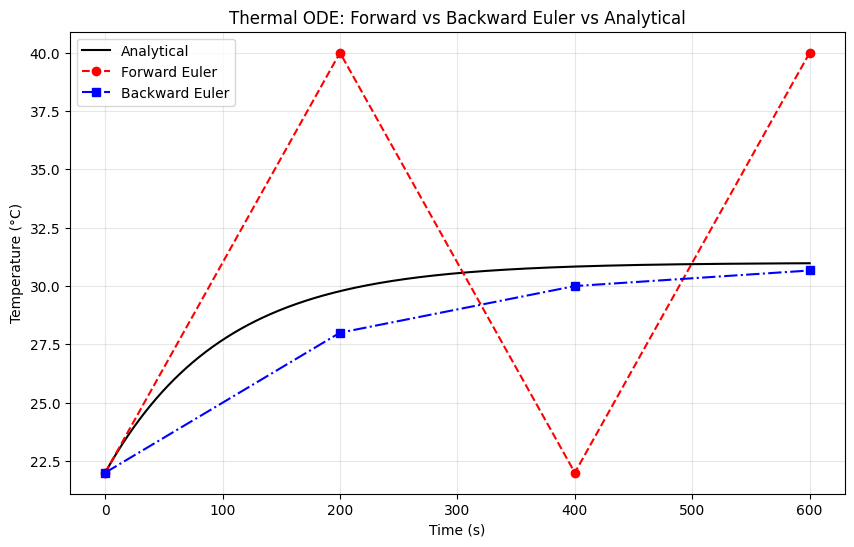

In [ ]:
# ---------------------------------------------------------
# Example usage + comparison plot
# ---------------------------------------------------------

# parameters
C = 500.0      # J/K
k = 5.0        # W/K
Ta = 22.0      # ambient
H = 45.0       # heater
T0 = 22.0      # initial

#TODO_STEP_3A amoung 5, 25, 75, 140 and 260 seconds
step = 260.0    # seconds
t_span = (0.0, 600.0)

rhs = make_thermal_rhs(C, k, Ta, H)

# numerical solutions
t_fe, T_fe, _ = fixed_step_scalar(rhs, t_span, T0, step, "euler",
                                  C=C, k=k, Ta=Ta, H=H)

t_be, T_be, _ = fixed_step_scalar(rhs, t_span, T0, step, "eulerback",
                                  C=C, k=k, Ta=Ta, H=H)

# analytical solution
t_exact = np.linspace(0, 600, 2000)
T_exact = exact_thermal_temperature(t_exact, T0, C, k, Ta, H)

# ---------------------------------------------------------
# Plot comparison
# ---------------------------------------------------------

plt.figure(figsize=(10,6))
plt.plot(t_exact, T_exact, 'k-', label="Analytical")
plt.plot(t_fe, T_fe, 'or--', label="Forward Euler")
plt.plot(t_be, T_be, 'sb-.', label="Backward Euler")
plt.xlabel("Time (s)")
plt.ylabel("Temperature (°C)")
plt.title("Thermal ODE: Forward vs Backward Euler vs Analytical")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()


## Activity 4A — Shooting Method

Consider the ODE:

$$ y''(x) = 0$$

with initial condition $y(0) = 0$ and a variable $y'(0)$.

What initial $y'(0)$ do you need to get $y(5) = 10$?

**This is the basis of the shooting method!**




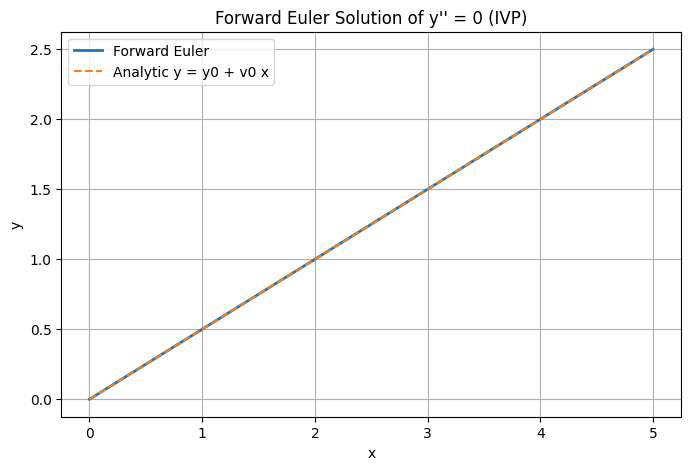

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

TODO_INITIAL_GRAD_4A = 0.5 # try 1.0, 2.0, 3.0, changing the initial gradient
# Parameters
y0 = 0.0
h = 0.01
N = 500

v0 = TODO_INITIAL_GRAD_4A

# Solve y'' = 0 as an IVP using forward Euler
# System:
#   y' = v
#   v' = 0

def euler_second_order_ypp_zero(y0, v0, h, N):
    xs = np.zeros(N+1)
    ys = np.zeros(N+1)
    vs = np.zeros(N+1)

    xs[0] = 0.0
    ys[0] = y0
    vs[0] = v0

    for n in range(N):
        xs[n+1] = xs[n] + h
        vs[n+1] = vs[n]        # v' = 0
        ys[n+1] = ys[n] + h*vs[n]

    return xs, ys, vs

xs, ys, vs = euler_second_order_ypp_zero(y0, v0, h, N)

# Analytic solution
analytic = y0 + v0 * xs

plt.figure(figsize=(8,5))
plt.plot(xs, ys, label="Forward Euler", linewidth=2)
plt.plot(xs, analytic, "--", label="Analytic y = y0 + v0 x")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Forward Euler Solution of y'' = 0 (IVP)")
plt.grid(True)
plt.legend()
plt.show()

Let's remove the manual **Guess Work**!

## Activity 5A — Boundary Value Problem Shooting Method





Once the update equations needed to provide an initial value solution for the dependent ODE variables, $y_1$ and $y_2$ are defined, and similar ODEs for the sensitivities of the solution to the unknown initial value are determined, the solution process works as follows.

The ODE is $$y'' = 0,$$

which can besolved as

$$\frac{\mbox{d}}{\mbox{d}x}\begin{bmatrix}y_1\\ y_2\end{bmatrix} = \begin{bmatrix}y_2\\ 0\end{bmatrix},$$

where $y_1 = y$ and $y_2 = y'$.

1. For a given $s_k$, integrate the **combined system** from $t=a$ to $x=b$:

    Main variables:
    $$y_1' = y_2,\qquad y_2' = 0,$$
    with
    $$y_1(a) = \alpha,\quad y_2(a) = s_n.$$

    Sensitivity variables:
    $$z_1' = z_2,\qquad z_2' = 0,$$
    with
    $$z_1(a) = 0,\quad z_2(a) = 1.$$

2. Update the guess $s_{n+1}$ using Newton's Method

    At $t=b$, compute:
    $$F(s_n) = y_1(b) - \beta,\qquad F'(s_n) = z_1(b).$$
    Update the shooting parameter:
    $$s_{n+1} = s_n - \frac{y_1(b) - \beta}{z_1(b)}.$$

3. Check the Magnitude of the Shooting Function

    While $|F(s_n)|$ is greater than a chosen tolerance

    Repeat steps 1–3.

4. Once $s_n$ has converged, the corresponding Initial value solution $y_1(t; s_n)$ is the numerical approximation of the Boundary Value Problem solution $y(x)$ on $[a,b]$.

In [ ]:
# --- 1. Define the Combined ODE System (y1, y2, z1, z2) ---
def combined_euler_step(y1, y2, z1, z2, h):
    # ODE for y
    dy1_dt = y2
    dy2_dt = 0

    # ODE for sensitivities (z = dy/ds)
    dz1_dt = z2
    dz2_dt = 0

    y1_new = y1 + dy1_dt * h
    y2_new = y2 + dy2_dt * h
    z1_new = z1 + dz1_dt * h
    z2_new = z2 + dz2_dt * h

    return y1_new, y2_new, z1_new, z2_new

# --- 2. Shooting Function (Solves IVP for a given initial_s) ---
def solve_bvp_shooting(initial_s, y1_a, t_start, t_end, h):
    # Initial conditions for y (main ODE)
    y1 = y1_a
    y2 = initial_s  # This is our 's' parameter

    # Initial conditions for z (sensitivities)
    z1 = 0.0  # z1(a) = dy1(a)/ds = d(alpha)/ds = 0
    z2 = 1.0  # z2(a) = dy2(a)/ds = ds/ds = 1

    n_steps = int((t_end - t_start) / h)

    # Store full trajectories for plotting the final solution
    t_values = np.linspace(t_start, t_end, n_steps + 1)
    y1_trajectory = np.zeros(n_steps + 1)
    y2_trajectory = np.zeros(n_steps + 1)

    y1_trajectory[0] = y1
    y2_trajectory[0] = y2

    # Integrate the combined system
    for i in range(n_steps):
        y1, y2, z1, z2 = combined_euler_step(y1, y2, z1, z2, h)
        y1_trajectory[i+1] = y1
        y2_trajectory[i+1] = y2

    # Return the values at the end point t_end (b)
    return y1, z1, y1_trajectory, t_values

# --- 3. Main Shooting Method with Newton's Iteration ---
def shooting_method_newton(y1_a, target_y_b, t_start, t_end, h, initial_guess_s, tol=1e-6, max_iter=100):
    s_k = initial_guess_s
    iterations = 0
    F_values = []
    s_values = []
    final_y1_trajectory = None
    final_t_values = None

    print(f"Starting Shooting Method (y(a)={y1_a}, y(b)={target_y_b})")

    for i in range(max_iter):
        iterations = i + 1
        y1_at_b, z1_at_b, current_y1_trajectory, t_values = solve_bvp_shooting(s_k, y1_a, t_start, t_end, h)

        F_sk = y1_at_b - target_y_b
        F_prime_sk = z1_at_b

        F_values.append(F_sk)
        s_values.append(s_k)

        print(f"Iter {iterations}: s_k = {s_k:.6f}, y1(b) = {y1_at_b:.6f}, F(s_k) = {F_sk:.6f}, F'(s_k) = {F_prime_sk:.6f}")

        if abs(F_sk) < tol:
            print(f"Converged in {iterations} iterations with s = {s_k:.6f}")
            final_y1_trajectory = current_y1_trajectory
            final_t_values = t_values
            break

        if F_prime_sk == 0:
            print("Warning: F'(s_k) is zero. Cannot proceed with Newton's method.")
            break

        s_k_plus_1 = s_k - F_sk / F_prime_sk
        s_k = s_k_plus_1
    else:
        print(f"Did not converge within {max_iter} iterations. Final s = {s_k:.6f}, F(s_k) = {F_sk:.6f}")
        final_y1_trajectory = current_y1_trajectory
        final_t_values = t_values

    return s_k, final_y1_trajectory, final_t_values, F_values, s_values


Try varying the initial guess and the target $y(1)=?$ value. Note how quickly this method can converge when you add the Newton based guess update.

Starting Shooting Method (y(a)=1.0, y(b)=-20)
Iter 1: s_k = 0.000000, y1(b) = 1.000000, F(s_k) = 21.000000, F'(s_k) = 1.000000
Iter 2: s_k = -21.000000, y1(b) = -20.000000, F(s_k) = -0.000000, F'(s_k) = 1.000000
Converged in 2 iterations with s = -21.000000


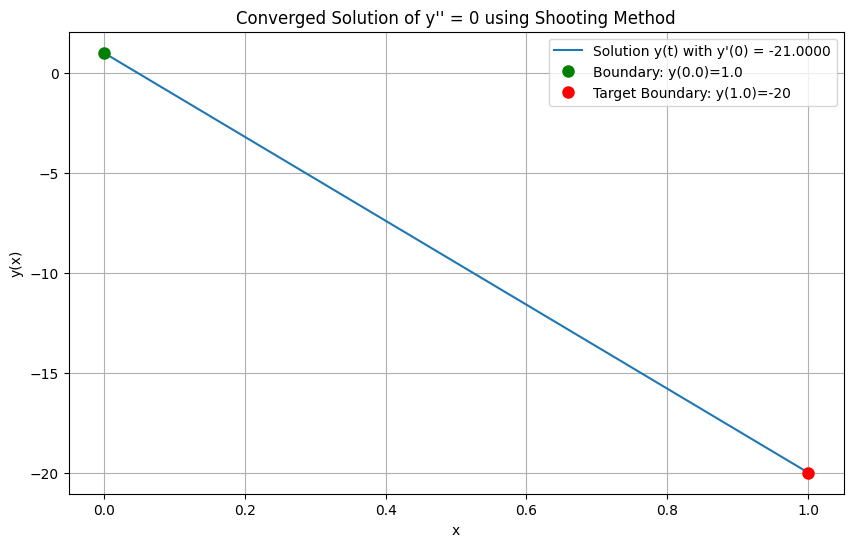

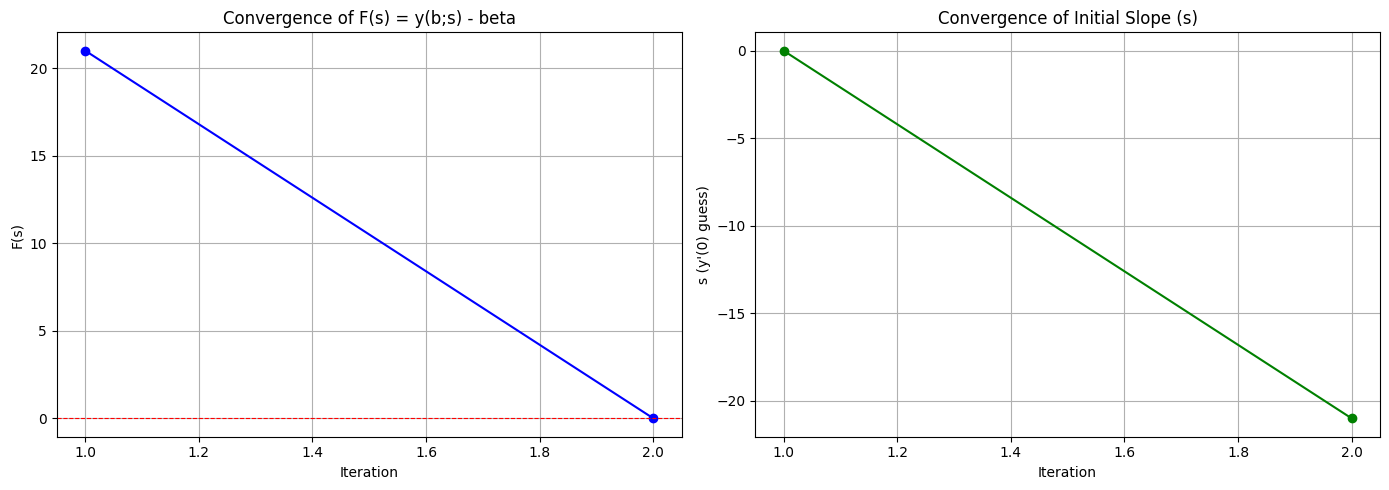

In [ ]:
# @title Shooting Method for y" = 0 with y(0) = 1, y(1)=4
guess_y2 = 0 # @param {"type":"number","placeholder":"0"}
import numpy as np
import matplotlib.pyplot as plt

TODO_TARGET_Y_AT_B = -20 # try [0, -10, 20, -20]

# --- Problem Parameters ---
y1_at_a = 1.0       # y(0) = 1
target_y_at_b = TODO_TARGET_Y_AT_B
t_a = 0.0           # Start time
t_b = 1.0           # End time (where boundary condition is applied)
h = 0.001           # Step size
initial_s_guess = guess_y2 # Initial guess for y'(0)

# --- Run the Shooting Method ---
converged_s, solution_trajectory, t_solution, F_history, s_history = shooting_method_newton(
    y1_at_a, target_y_at_b, t_a, t_b, h, initial_s_guess
)

# --- Plotting Results ---

# Plot the converged solution
fig1 = plt.figure(figsize=(10, 6))
plt.plot(t_solution, solution_trajectory, label=f'Solution y(t) with y\'(0) = {converged_s:.4f}')
plt.plot(t_a, y1_at_a, 'go', markersize=8, label=f'Boundary: y({t_a})={y1_at_a}')
plt.plot(t_b, target_y_at_b, 'ro', markersize=8, label=f'Target Boundary: y({t_b})={target_y_at_b}')
plt.title("Converged Solution of y'' = 0 using Shooting Method")
plt.xlabel('x')
plt.ylabel('y(x)')
plt.legend()
plt.grid(True)
plt.show()

# Plot the convergence of F(s) and s
fig2, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(F_history) + 1), F_history, 'b-o')
axes[0].axhline(0, color='red', linestyle='--', linewidth=0.8)
axes[0].set_title('Convergence of F(s) = y(b;s) - beta')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('F(s)')
axes[0].grid(True)

axes[1].plot(range(1, len(s_history) + 1), s_history, 'g-o')
axes[1].set_title('Convergence of Initial Slope (s)')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('s (y\'(0) guess)')
axes[1].grid(True)

plt.tight_layout()
plt.show()


# 🟩 Wednesday practical — problem solving

Activities 1B–5B consist of analytical funtions as well as provide data, candidate settings, helper functions and progressive hints.

Some problem will need to be solved on paper, other will require replace each runnable starter selection with a defensible answer and explain the evidence.


## Activity 1B — Using perturbation analysis to determine the stability margins of ODE Solutions.

**Problem:**

A small electronic component is heated by a constant power source with power input $H$ and loses heat to ambient via Newton cooling. The temperature satisfies
$$ \frac{dT}{dt} = -k(T - T_a) + \frac{H}{C},$$
where $T$ is the temperature (in °C or K) of the component, $T_a$ is the ambient temperature of the surrounding, $k$ is the heat loss coefficient, and $C$ is the heat capacity of the system.  


Task:
1. Discretise the soltuion using Forward Euler, Two‑Step Euler, and a Heun / Improved Euler (RK2).
    - write these out as you would likely evaluate them in practice.
2. Introduce a perturbation $$T_n \to T_n + \delta_n $$ and derive the perturbation evolution equation for each method.
3. Determine stability conditions on the timestep $h$.
4. Comment on which method is most robust for stiff thermal systems.
5. Run the following codes for each method and comment on the following
    * For which values of [ h ] does Forward Euler blow up?
    * Does AB2 become unstable earlier than Forward Euler?
    * Does Heun RK2 remain stable for slightly larger [ h ]?
    * Which method tracks the analytical curve most closely?
    * How does the error scale as [ h ] decreases?
    * Does RK2 converge faster than FE and AB2?

**Hints:**

* The two-step Euler Method is otherwise knowns as the standard explicit *2-step Adams-Bashforth method*:
$$ x_{n+1} = x_n + h\left(\frac{3}{2}f_n - \frac{1}{2}f_{n-1}\right),$$
where $f_n$ is $dT/dt$.

* The two-point Heun / Improved Euler (RK2) is
    * $k_1 = f(x_n)$
    * $k_2 = f\big(x_n +  hk_1\big)$
    * $x_{n+1} = x_n + \frac{h}{2}(k_1+k_2)$

* For the two-step method you may need to assume and amplification factor between the n-th step and initial perturbation,
$$\delta_n = A^n \delta_0$$

Enter step size h (e.g. 0.1, 0.5, 1.0, 2.0): 1.0


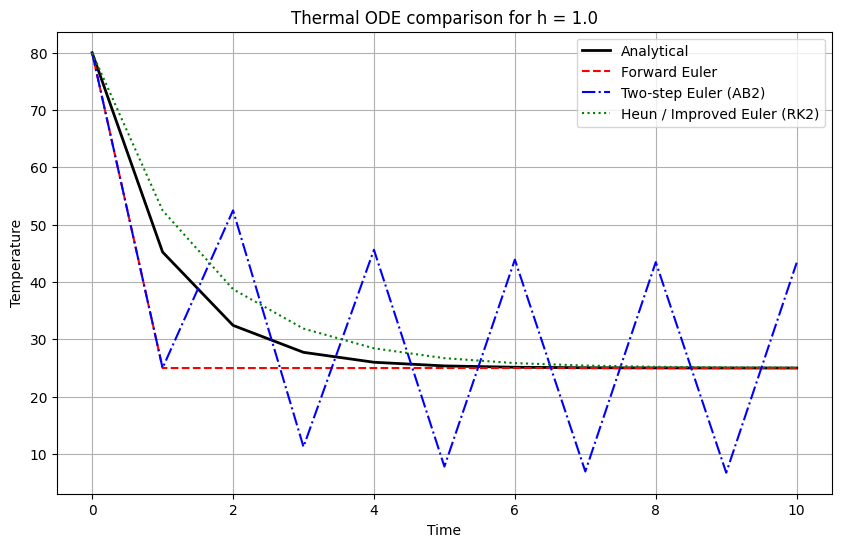


Final-time errors:
Forward Euler error: 0.0025
AB2 error:           18.3666
Heun RK2 error:      0.0512


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# Thermal ODE parameters
# ---------------------------------------------------------
k = 1.0          # cooling constant
Ta = 20.0        # ambient temperature
H = 50.0         # heating power
C = 10.0         # heat capacity

# equilibrium temperature
T_inf = Ta + H/(k*C)

# initial condition
T0 = 80.0

# ---------------------------------------------------------
# Analytical solution
# ---------------------------------------------------------
def T_analytic(t):
    return T_inf + (T0 - T_inf)*np.exp(-k*t)

# ---------------------------------------------------------
# Forward Euler
# ---------------------------------------------------------
def forward_euler(h, t_end):
    N = int(t_end/h)
    T = np.zeros(N+1)
    T[0] = T0
    for n in range(N):
        f_n = -k*(T[n] - Ta) + H/C
        T[n+1] = T[n] + h*f_n
    return T

# ---------------------------------------------------------
# Two-step Euler (AB2)
# ---------------------------------------------------------
def ab2(h, t_end):
    N = int(t_end/h)
    T = np.zeros(N+1)
    T[0] = T0

    # bootstrap first step using Forward Euler
    f0 = -k*(T[0] - Ta) + H/C
    T[1] = T[0] + h*f0

    for n in range(1, N):
        f_n = -k*(T[n] - Ta) + H/C
        f_nm1 = -k*(T[n-1] - Ta) + H/C
        T[n+1] = T[n] + h*(1.5*f_n - 0.5*f_nm1)
    return T

# ---------------------------------------------------------
# Heun / Improved Euler (RK2)
# ---------------------------------------------------------
def heun_rk2(h, t_end):
    N = int(t_end/h)
    T = np.zeros(N+1)
    T[0] = T0
    for n in range(N):
        k1 = -k*(T[n] - Ta) + H/C
        T_pred = T[n] + h*k1
        k2 = -k*(T_pred - Ta) + H/C
        T[n+1] = T[n] + 0.5*h*(k1 + k2)
    return T

# ---------------------------------------------------------
# Run comparison for a chosen h
# ---------------------------------------------------------
h = float(input("Enter step size h (e.g. 0.1, 0.5, 1.0, 2.0): "))
t_end = 10
t = np.linspace(0, t_end, int(t_end/h)+1)

T_fe = forward_euler(h, t_end)
T_ab2 = ab2(h, t_end)
T_rk2 = heun_rk2(h, t_end)
T_exact = T_analytic(t)

# ---------------------------------------------------------
# Plot results
# ---------------------------------------------------------
plt.figure(figsize=(10,6))
plt.plot(t, T_exact, 'k-', label="Analytical", linewidth=2)
plt.plot(t, T_fe, 'r--', label="Forward Euler")
plt.plot(t, T_ab2, 'b-.', label="Two-step Euler (AB2)")
plt.plot(t, T_rk2, 'g:', label="Heun / Improved Euler (RK2)")

plt.xlabel("Time")
plt.ylabel("Temperature")
plt.title(f"Thermal ODE comparison for h = {h}")
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# Error at final time
# ---------------------------------------------------------
print("\nFinal-time errors:")
print(f"Forward Euler error: {abs(T_fe[-1] - T_exact[-1]):.4f}")
print(f"AB2 error:           {abs(T_ab2[-1] - T_exact[-1]):.4f}")
print(f"Heun RK2 error:      {abs(T_rk2[-1] - T_exact[-1]):.4f}")


## Activity 2B — Implicit Method for a Stiff ODE

**Problem:** During the deployment of a satellite's lightweight solar array, a flexible hinge is equipped with a viscoelastic damper to suppress high-frequency vibrations. After linearisation, the hinge's rotational motion is approximated by the first-order ODE
$$ \frac{d\theta}{dt} = -\gamma\,\theta + M(t),
\qquad \theta(0)=\theta_0,
$$
where
* $\theta(t) $ is the hinge rotation angle,
* $ \gamma $ is an effective viscoelastic damping coefficient,
* $ M(t) $ is a small residual actuation torque.

1. Formulate an Implicit Euler Method to solve for the hinge angle as a function of time, based on the initial angle.

2. Formulate an Implicit Heun method to solve for the hinge angle as a function of time, based on the initial angle.

3. Use perturbation analysis to determine the stability margins for both the Implicit Euler and Heun Method.

4. Fill in the missing functions in the code below to create an implicit solver for the solar panel hinge.

Take:
$$ \gamma = 120, \qquad M(t) = 0.5\cos(20t).$$

**Hints:**

* The implicit Heun Method is
  $$x_{n+1} = x_n + \frac{h}{2}(f_n+f_{n+1})$$

In [ ]:
import numpy as np

# ---------------------------------------------------------
# Problem parameters (students may modify these)
# ---------------------------------------------------------
gamma = 120.0                 # damping coefficient
def M(t):                     # residual torque
    return 0.5 * np.cos(20*t)

# ---------------------------------------------------------
# Time discretisation
# ---------------------------------------------------------
t0 = 0.0
tf = 1.0
h  = 0.001
N  = int((tf - t0) / h)

# Storage
t = np.linspace(t0, tf, N+1)
theta_euler = np.zeros(N+1)
theta_heun  = np.zeros(N+1)

# Initial condition
theta0 = 0.1
theta_euler[0] = theta0
theta_heun[0]  = theta0

# ---------------------------------------------------------
# FUNCTIONS STUDENTS MUST COMPLETE
# ---------------------------------------------------------

def implicit_euler_step(theta_n, t_np1, h, gamma):
    """
    Perform ONE implicit Euler step.

    Students must implement:
        theta_{n+1} = (theta_n + h*M(t_{n+1})) / (1 + h*gamma)
    """
    # TODO: implement implicit Euler update
    raise NotImplementedError


def implicit_heun_step(theta_n, t_n, t_np1, h, gamma):
    """
    Perform ONE implicit Heun (trapezoidal RK2) step.

    Students must implement:
        theta_{n+1} = [theta_n + (h/2)( -gamma*theta_n + M(t_n)
                                      -gamma*theta_{n+1} + M(t_{n+1}) )]
                      / (1 + h*gamma/2)

    Note: theta_{n+1} appears on both sides → solve algebraically.
    """
    # TODO: implement implicit Heun update
    raise NotImplementedError


# ---------------------------------------------------------
# MAIN TIME-STEPPING LOOP
# ---------------------------------------------------------

for n in range(N):
    # Implicit Euler
    theta_euler[n+1] = implicit_euler_step(theta_euler[n], t[n+1], h, gamma)

    # Implicit Heun RK2
    theta_heun[n+1]  = implicit_heun_step(theta_heun[n], t[n], t[n+1], h, gamma)


# ---------------------------------------------------------
# Plotting (optional)
# ---------------------------------------------------------
import matplotlib.pyplot as plt

plt.plot(t, theta_euler, label="Implicit Euler")
plt.plot(t, theta_heun, label="Implicit Heun RK2")
plt.xlabel("t")
plt.ylabel("theta(t)")
plt.legend()
plt.show()


## Activity 3B — Boundary Value Problem - Shooting Method

**Problem:** constraint
Consider a simplified planar ascent of a rocket in a vertical plane. The vehicle's position $ (x(t), z(t)) $ and flight-path angle $ \gamma(t) $ evolve according to
$$\dot{x} = V \cos\gamma,
$$
$$\dot{z} = V \sin\gamma,
$$
$$\dot{\gamma} = \frac{L}{mV} - \frac{g}{V}\cos\gamma,
$$
where:
* $ V $ is the (assumed constant) speed,
* $ m $ is the mass (constant over the short maneuver),
* $ L $ is the lift force (treated as a control input),
* $ g $ is gravitational acceleration.
We assume the control systems provide commands a constant lift coefficient $ C_L $, so that
$$ L = \frac{1}{2}\rho S C_L V^2, $$
with $ \rho $ the air density and $ S $ the reference area. Over the short maneuver, take $ \rho $ as constant.

We want to transfer the vehicle from an initial state at $ t=0 $:
$$x(0) = 0, \quad z(0) = z_0, \quad \gamma(0) = \gamma_0,$$
to a desired terminal flight-path angle at time $ t = T $:
$$ \gamma(T) = \gamma_f,$$

The unknown parameter is the constant lift coefficient $ C_L $. The ODE system is initial value in $ (x,z,\gamma) $ but the terminal condition $ \gamma(T)=\gamma_f $ makes it a boundary value problem in terms of the parameter $ C_L $.

1. Show that if you define the state ODE as $\frac{d\mathbf{y}}{dt} = \mathbf{f}(t, \mathbf{y}, s)$, where $\mathbf{y}(t) = [x,z,\gamma]^T$, and $s$ is the initial guess, then the ODEs required to integrate sensitivity terms, $ \mathbf{z}(t) = \frac{\partial \mathbf{y}(t)}{\partial s}$, can be expressed as $$ \frac{d\mathbf{z}}{dt}
=
\frac{\partial \mathbf{f}}{\partial \mathbf{y}}\mathbf{z}
+
\frac{\partial \mathbf{f}}{\partial s}.
$$
2. Determine the initial conditions for the sensitivity terms.

3. Define the shooting function and the iterative update that will be required of the initial guess $s$, in terms of the sensitivity parameters.

4. State the full system of ODEs that need to be solved for the shooting method along with all initial conditions.

5. Examine the Code below and look at how the terms from 1-4 are utilised.
    * what method has been used to solve the IVP?
    * it is implicit or explicit?
    * how has the step size been chosen?


**Hints:**

* From the chain rule:
$$\frac{\partial \mathbf{f}}{\partial s}(t, \mathbf{y}, s) = \frac{\partial \mathbf{f}}{\partial \mathbf{y}}\frac{\partial \mathbf{y}}{\partial s}+\frac{\partial \mathbf{f}}{\partial s}$$
* the term $ \frac{\partial \mathbf{f}}{\partial \mathbf{y}} $ is the Jacobian matrix of $ \mathbf{f} $ with respect to the state $ \mathbf{y} $:
$$ \frac{\partial \mathbf{f}}{\partial \mathbf{y}}
=
\begin{bmatrix}
\frac{\partial f_1}{\partial y_1} & \cdots & \frac{\partial f_1}{\partial y_n}\\
\vdots & \ddots & \vdots\\
\frac{\partial f_n}{\partial y_1} & \cdots & \frac{\partial f_n}{\partial y_n}
\end{bmatrix}.
 $$


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# -----------------------------
# Problem parameters
# -----------------------------
g   = 9.81          # gravitational acceleration [m/s^2]
rho = 1.225         # air density [kg/m^3]
S   = 10.0          # wing reference area [m^2]
m   = 1000.0        # mass [kg]
V   = 300.0         # flight speed [m/s]

T   = 20.0          # final time [s]

# Initial conditions
x0      = 0.0                       # horizontal position [m]
z0      = 1000.0                    # altitude [m]
gamma0  = np.deg2rad(10.0)          # initial flight-path angle [rad]
gamma_f = np.deg2rad(30.0)          # desired terminal flight-path angle [rad]

# -----------------------------
# ODE system: state + sensitivity
# -----------------------------
def rhs(t, Y, CL):
    x, z, gamma, sx, sz, sgamma = Y

    # State dynamics
    L = 0.5 * rho * S * CL * V**2
    dxdt   = V * np.cos(gamma)
    dzdt   = V * np.sin(gamma)
    dgamdt = (L / (m * V)) - (g / V) * np.cos(gamma)

    # Jacobian df/dy
    A = np.array([
        [0.0, 0.0, -V * np.sin(gamma)],
        [0.0, 0.0,  V * np.cos(gamma)],
        [0.0, 0.0,  (g / V) * np.sin(gamma)]
    ])

    # df/dCL
    df_dCL = np.array([0.0, 0.0, (rho * S * V) / (2.0 * m)])

    s_vec = np.array([sx, sz, sgamma])
    dsdt_vec = A @ s_vec + df_dCL

    return [dxdt, dzdt, dgamdt, dsdt_vec[0], dsdt_vec[1], dsdt_vec[2]]


# -----------------------------
# Integrate for given CL
# -----------------------------
def integrate_for_CL(CL):
    Y0 = [x0, z0, gamma0, 0.0, 0.0, 0.0]
    sol = solve_ivp(rhs, [0.0, T], Y0, args=(CL,), dense_output=True,
                    rtol=1e-8, atol=1e-10)
    return sol


# -----------------------------
# Shooting iterations
# -----------------------------
CL = 0.1
max_iter = 8
tol = 1e-8

plt.figure(figsize=(10, 6))

print("Iter |   CL        | gamma(T) [deg] | residual [deg] | sensitivity dPhi/dCL")
print("-----+------------+----------------+----------------+----------------------")

for k in range(max_iter):

    sol = integrate_for_CL(CL)
    xT, zT, gammaT, sxT, szT, sgammaT = sol.y[:, -1]

    residual = gammaT - gamma_f
    res_deg = np.rad2deg(residual)
    gamma_deg = np.rad2deg(gammaT)

    dPhi_dCL = sgammaT

    print(f"{k:4d} | {CL:10.6f} | {gamma_deg:14.6f} | {res_deg:14.6e} | {dPhi_dCL:22.6e}")

    # Plot trajectory for this iteration
    t_plot = np.linspace(0, T, 400)
    Y_plot = sol.sol(t_plot)
    x_plot = Y_plot[0]
    z_plot = Y_plot[1]

    plt.plot(x_plot, z_plot, label=f"Iteration {k} (CL={CL:.4f})")

    if abs(residual) < tol:
        break

    # Newton update
    CL = CL - residual / dPhi_dCL

plt.xlabel("x (m)")
plt.ylabel("z (m)")
plt.title("Rocket Flight Path at Each Shooting Iteration")
plt.legend()
plt.grid(True)
plt.show()

print("\nFinal CL =", CL)
final_sol = integrate_for_CL(CL)
gammaT_final = final_sol.y[2, -1]
print("Final gamma(T) [deg] =", np.rad2deg(gammaT_final))
print("Target gamma_f [deg] =", np.rad2deg(gamma_f))


# ⬛ Revision and home study

Finish incomplete B activities before attempting the questions below. Answers should use
units, numerical evidence and physical interpretation—not only method names.


## 📝 Activity 4 — Test-style short problems

1.  For the ODE $y'(t) = A y(t) + B \sin(t)$, if $A = -50$, what is the approximate stability limit for the step size `h` when using Forward Euler?
2.  What characterises an Ordinary Differential Equation as 'stiff' in the context of numerical solutions?
3.  Compare the stability of an Explicit Euler method versus an Implicit Euler method for a problem like $\frac{d\theta}{dt} = -\gamma\,\theta + M(t)$.
4.  In the analytical solution of $y'(t) = A y(t) + B \sin(t)$, what are the two main components, and which one decays rapidly when $A \ll 0$?
5.  In the shooting method for Boundary Value Problems, what is the primary purpose of deriving and integrating sensitivity functions (e.g., $z_1', z_2'$)?
6.  If using Implicit Euler with a very large step size `h`, what qualitative effect might be observed on the accuracy of the solution, even if it remains stable?
7.  How many right-hand-side evaluations does one step of the Heun/Improved Euler (RK2) method typically require?
8.  Convert the second-order ODE $m\ddot{x} + b\dot{x} + kx = F(t)$ into a system of two first-order ODEs, defining appropriate state variables.
9.  What impact does the coefficient $A$ have on the initial transient behavior in $y'(t) = A y(t) + B \sin(t)$, especially when $A$ is a large negative number?
10. Briefly explain the fundamental difference between an Initial Value Problem (IVP) and a Boundary Value Problem (BVP) in terms of specified conditions.

## 🧪 Activity 5 — Integrated method-selection challenge

For each scenario, choose a starting workflow and one validation check:

1.  **Modeling a rapidly decaying transient in a stiff system**: You need to accurately capture the initial behavior of a system with a very large negative 'A' value (e.g., A = -1000) using a fixed-step explicit method, but then efficiently simulate its long-term, slow-varying response.
2.  **Solving a boundary value problem where the initial derivative is unknown**: You have a second-order ODE with conditions specified at both the start and end of the interval, and you need to find the correct initial slope to satisfy the end condition.
3.  **Simulating a thermal system where stability is paramount, even with large time steps**: The system has a characteristic time constant, and you are concerned about numerical blow-up, but the computational cost of very small steps is prohibitive.
4.  **Converting a second-order mechanical system into a form suitable for standard ODE solvers**: A mass-spring-damper system is described by a single second-order differential equation, and you want to use a first-order solver.
5.  **Analyzing the stability limits of a new explicit method for a given ODE**: You have developed a custom explicit Euler-like solver for $y'(t) = Ay(t)$, and you need to determine the maximum step size `h` before numerical instability occurs.
6.  **Predicting the long-term, steady-state response of a forced ODE with a known analytical solution**: You are interested in the periodic behavior of $y'(t) = Ay(t) + B\sin(t)$ after the initial transient has decayed, and you want to quickly verify numerical results against the analytical forced component.

State what information is measured, assumed, fitted and numerically calculated.

## ✅ Week 9 completion checklist

- [ ] I can explain the stability limits of explicit Euler for stiff ODEs like $y'(t) = Ay(t) + B\sin(t)$.
- [ ] I understand how to decompose an analytical solution into transient and steady-state components to identify stiffness.
- [ ] I can formulate and implement Implicit Euler and Implicit Heun methods for a given ODE.
- [ ] I can perform perturbation analysis to determine the stability conditions for explicit and implicit methods.
- [ ] I can distinguish between the stability and accuracy of different numerical ODE solvers.
- [ ] I can describe the concept of a stiff ODE and its implications for numerical integration.
- [ ] I can formulate a Boundary Value Problem (BVP) as an Initial Value Problem (IVP) using the shooting method.
- [ ] I can derive and integrate sensitivity equations for parameter updates in the shooting method.
- [ ] I can set up the full system of ODEs and initial conditions for a shooting method with Newton's iteration.
- [ ] I can convert higher-order ODEs into a system of first-order ODEs.
- [ ] I can assess the robustness of different numerical methods for stiff thermal systems.
- [ ] I can select an appropriate ODE solution method based on problem characteristics (e.g., stiffness, BVP vs. IVP, desired stability/accuracy).

# 📚 References and data provenance

Method definitions and APIs follow the official NumPy and SciPy documentation referenced
in Notes 9.1–9.4. All examples are synthetic,
deterministic and generated in code. They expose numerical behaviour and are not
measurements for engineering design.

# 🤖 AI acknowledgement

Generative AI assisted with drafting, code development and editorial review. Activities,
numerical behaviour and tutor solutions were checked for alignment with the Week 9 notes
and unit learning outcomes.
